# Proyecto: Métodos tipo Monte Carlo

**Asignatura:** Métodos Numéricos, 2.º iMAT B (ICAI, curso 2025–2026) · **Grupo:** 4

**Autores:** Javier Martínez Montelongo, Ignacio Mascarell Agúndez, Juan Tabuyo Castell, Jaime Tuesta de Simón, Yago Vallarino Fernández-Cavada

---

## Índice

| Sección | Ejercicios | Contenido |
|---|---|---|
| 1 | 1–2 | Método de Monte Carlo e integrales de prueba |
| 2 | 3 | Estadísticas de múltiples ejecuciones |
| 3 | 4–5 | Estudio de convergencia |
| 4 | 6 | Estimación de π |
| 5 | 7 | Visualización del error |
| 6 | 8 | Orden de convergencia |
| 7 | 9–11 | Método hit-or-miss (aceptación–rechazo) |
| 8 | 12 | Función con pico estrecho |
| 9 | 13 | Visualización del muestreo |
| 10 | 14 | Análisis del error (pico estrecho) |
| 11 | 15 | Importance sampling |
| 12 | 16 | Importance sampling sobre el pico estrecho |
| 13 | 17 | Uniforme vs. gaussiana |
| 14 | 18 | Monte Carlo vs. regla del rectángulo |
| 15 | 19 | Monte Carlo para integrales dobles |
| 16 | 20 | Aplicaciones del MC 2D |
| 17 | 21 | MC en dominio no rectangular (disco) |
| 18 | 22 | Regla del rectángulo 2D vs. MC en el disco |
| 19 | 23 | MC en dimensión alta |
| 20 | 24 | Coste computacional en dimensión alta |


## Importaciones y semilla

Librerías necesarias para los cálculos numéricos y las visualizaciones. Se fija una semilla del generador aleatorio de NumPy para que los resultados sean reproducibles: con otra semilla, los valores numéricos cambian ligeramente, aunque las conclusiones se mantienen.

In [1]:
import random
import numpy as np
from matplotlib import pyplot as plt
from scipy.special import erf
from scipy.integrate import quad, dblquad
from scipy.stats import norm
import time

SEED = 0
np.random.seed(SEED)   # semilla fija para reproducir exactamente los resultados


---

## Sección 1 — Método de Monte Carlo e Integrales de Prueba (Ej. 1–2)

Se implementa la fórmula básica del método de Monte Carlo:

$$
\int_a^b f(x)\,dx \approx (b-a)\,\frac{1}{n}\sum_{i=1}^{n} f(x_i), \quad x_i \sim \mathcal{U}(a,b)
$$

Se prueba sobre tres funciones con valor exacto conocido.

In [2]:
#EJERCICIO 1 - Integración de Monte Carlo

def aproximacion_integral(f, a, b, n):
    h = (b - a) / n
    x_i = np.random.uniform(a, b, n)
    return h * np.sum(f(x_i))



# EJERCICIO 2

funciones = [
    (lambda x: x**2,      0, 1,      1/3,       "x²"),
    (lambda x: np.sin(x), 0, np.pi,  2.0,       "sin(x)"),
    (lambda x: np.exp(x), 0, 1,      np.e - 1,  "e^x"),
]
n = 10000

for f, a, b, exacto, nombre in funciones:
    aprox = aproximacion_integral(f, a, b, n)
    error = abs(aprox - exacto)
    print(f"∫{nombre}: aprox = {aprox:.5f}, exacto = {exacto:.5f}, error = {error:.5f}")


∫x²: aprox = 0.33033, exacto = 0.33333, error = 0.00300
∫sin(x): aprox = 1.98056, exacto = 2.00000, error = 0.01944
∫e^x: aprox = 1.71969, exacto = 1.71828, error = 0.00140


---

## Sección 2 — Estadísticas de Múltiples Ejecuciones (Ej. 3)

Al ser un método estocástico, cada ejecución produce un resultado diferente.  
Se repite el experimento *i* veces y se calculan la **media** y la **varianza** de las estimaciones.

In [3]:
# EJERCICIO 3

def ejecutar_varias_veces(f, a, b, n, i):
    resultados = []
    for _ in range(i):
        resultado = aproximacion_integral(f, a, b, n)
        resultados.append(resultado)
    return resultados

def calcular_estadisticas(resultados):
    media = np.mean(resultados)
    varianza_muestral = np.var(resultados, ddof=1)
    return media, varianza_muestral

# Ejemplo: x² dx de 0 a 1 con n=10000, ejecutado 10 veces
f = lambda x: x**2
a3 = 0
b3 = 1
n3 = 10000
veces = 10
resultados = ejecutar_varias_veces(f, a3, b3, n3, veces)
media, varianza = calcular_estadisticas(resultados)
print(f"Resultados de ejecutar la aproximación de la integral en {veces} veces")
for idx, res in enumerate(resultados, 1):
    print(f"Ejecución {idx}: Aproximación = {res}")
    
print(f"Media: {media}, Varianza: {varianza}")


Resultados de ejecutar la aproximación de la integral en 10 veces
Ejecución 1: Aproximación = 0.3308676359493113
Ejecución 2: Aproximación = 0.33299832384544553
Ejecución 3: Aproximación = 0.3317243632638097
Ejecución 4: Aproximación = 0.3336092892778177
Ejecución 5: Aproximación = 0.33462222356993604
Ejecución 6: Aproximación = 0.334957128831692
Ejecución 7: Aproximación = 0.33683213339104795
Ejecución 8: Aproximación = 0.3379081338429348
Ejecución 9: Aproximación = 0.33743878942983674
Ejecución 10: Aproximación = 0.33436536939427214
Media: 0.3345323390796104, Varianza: 5.540989235424584e-06


---

## Sección 3 — Estudio de Convergencia (Ej. 4–5)

Se analiza cómo evolucionan la media y la varianza al aumentar *n*.  
La teoría predice que el error estándar decae como $O(n^{-1/2})$.

In [4]:
#EJERCICIO 4, 5
for n_test in [100, 1000, 10000, 100000]:
    resultados_test = ejecutar_varias_veces(f, a3, b3, n_test, 50)
    media_test, varianza_test = calcular_estadisticas(resultados_test)
    print(f"n={n_test}: media={media_test:.5f}, varianza={varianza_test:.8f}")

print("Se observa que al aumentar n, la varianza disminuye significativamente")

n=100: media=0.33447, varianza=0.00065485
n=1000: media=0.33528, varianza=0.00009916
n=10000: media=0.33328, varianza=0.00001000
n=100000: media=0.33332, varianza=0.00000087
Se observa que al aumentar n, la varianza disminuye significativamente


---

## Sección 4 — Estimación de π (Ej. 6)

Se utiliza la identidad:

$$
\pi = \int_0^1 4\sqrt{1-x^2}\,dx
$$

para estimar π mediante Monte Carlo con distintos valores de *n*.

In [5]:
#EJERCICIO 6
f6 = lambda x: 4 * np.sqrt(1 - x**2)

a6, b6 = 0, 1
valor_exacto = np.pi
valores_n = sorted(m * 10**i for i in range(1, 7) for m in (1, 5))
aproximaciones = []
errores = []
for n6 in valores_n:
    # usamos media de 30 ejecuciones para suavizar la aleatoriedad
    muestra = [aproximacion_integral(f6, a6, b6, n6) for _ in range(30)]
    resultado = np.mean(muestra)
    error = abs(resultado - valor_exacto)
    aproximaciones.append(resultado)
    errores.append(error)
    print(f"Resultado: {resultado:.10f} para n={n6}, error absoluto: {error:.6f}, error relativo: {error/valor_exacto:.6f}")






Resultado: 3.1398426574 para n=10, error absoluto: 0.001750, error relativo: 0.000557
Resultado: 3.1185322266 para n=50, error absoluto: 0.023060, error relativo: 0.007340
Resultado: 3.1263963195 para n=100, error absoluto: 0.015196, error relativo: 0.004837
Resultado: 3.1403607739 para n=500, error absoluto: 0.001232, error relativo: 0.000392
Resultado: 3.1454497711 para n=1000, error absoluto: 0.003857, error relativo: 0.001228
Resultado: 3.1419805810 para n=5000, error absoluto: 0.000388, error relativo: 0.000123
Resultado: 3.1434284161 para n=10000, error absoluto: 0.001836, error relativo: 0.000584
Resultado: 3.1416162048 para n=50000, error absoluto: 0.000024, error relativo: 0.000007
Resultado: 3.1416492394 para n=100000, error absoluto: 0.000057, error relativo: 0.000018
Resultado: 3.1417831716 para n=500000, error absoluto: 0.000191, error relativo: 0.000061
Resultado: 3.1417630084 para n=1000000, error absoluto: 0.000170, error relativo: 0.000054
Resultado: 3.1416033547 para 

---

## Sección 5 — Visualización del Error (Ej. 7)

Se representa gráficamente el error en función de *n* en escala log-log,  
junto con la curva de referencia $O(n^{-1/2})$.

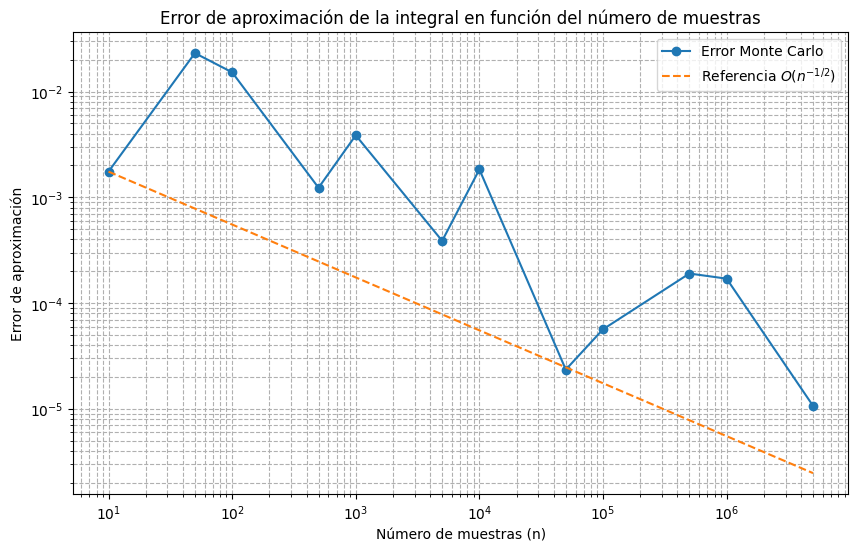

In [6]:
# EJERCICIO 7

def representar_errores(valores_n, errores):
    referencia = [errores[0] * (valores_n[0]/n)**0.5 for n in valores_n]
    plt.figure(figsize=(10,6))
    plt.plot(valores_n, errores, marker='o', label='Error Monte Carlo')
    plt.plot(valores_n, referencia, '--', label=r'Referencia $O(n^{-1/2})$')
    plt.xscale('log')
    plt.yscale('log')
    plt.xlabel('Número de muestras (n)')
    plt.ylabel('Error de aproximación')
    plt.title('Error de aproximación de la integral en función del número de muestras')
    plt.legend()
    plt.grid(True, which="both", ls="--")
    plt.show()

representar_errores(valores_n, errores)

---

## Sección 6 — Orden de Convergencia (Ej. 8)

Se calcula numéricamente la pendiente en escala log-log entre pares de puntos consecutivos  
para verificar que el orden de convergencia experimental es $-\tfrac{1}{2}$.

In [7]:
# EJERCICIO 8

#para obtener el orden de convergencia, queremos verificar si el error se comporta con O(n^(-1/2)) por tanto con pendiente -1/2.
#analizando la pendiente entre cada par de puntos consecutivos de valores_n, error, en forma logarítmica

# error = c * n ^(-1/2)
# log(error) = log(c) + -1/2 * log(n)
# y que es una funcion y = mx + b siendo m la pendiente (-1/2) que queremos estimar

errores8 = []
for n8 in valores_n:
    muestra = [abs(aproximacion_integral(f6, a6, b6, n8) - valor_exacto) for _ in range(30)]
    errores8.append(np.mean(muestra))

pendientes = []
for i in range(len(errores8)-1):
    num = np.log(errores8[i+1]) - np.log(errores8[i])
    den = np.log(valores_n[i+1]) - np.log(valores_n[i])
    pendientes.append(num/den)

print(f"Pendientes estimadas: {[round(float(p), 3) for p in pendientes]}")
print(f"Pendiente media: {round(np.mean(pendientes), 3)}")
print("Valor teórico esperado: -0.500")

Pendientes estimadas: [-0.413, -0.906, -0.502, -0.172, -0.759, -0.003, -0.595, -0.289, -0.488, -0.603, -0.563]
Pendiente media: -0.481
Valor teórico esperado: -0.500


---

## Sección 7 — Método Hit-or-Miss (Ej. 9–11)

Variante geométrica del método de Monte Carlo.  
Se generan puntos aleatorios en un rectángulo envolvente y se cuenta  
la fracción que cae por debajo de la curva:

$$
\int_a^b f(x)\,dx \approx (b-a)\cdot M \cdot \frac{\#\{y_i \leq f(x_i)\}}{n}
$$

In [8]:
# EJERCICIO 9
# Genera n puntos aleatorios uniformes en el rectángulo [a, b] × [0, M]
def puntos_aleatorio_rectangulo(a, b, M, n):
    x = np.random.uniform(a, b, n)
    y = np.random.uniform(0, M, n)
    return np.column_stack((x, y))


# EJERCICIO 10
# Determina qué puntos satisfacen y ≤ f(x) y aproxima el área bajo la curva
def puntos_validos(f, puntos):
    x = puntos[:,0]
    y = puntos[:,1]
    mask = y <= f(x)
    return puntos[mask]

def proporcion(f, a, b, M, n):
    puntos = puntos_aleatorio_rectangulo(a, b, M, n)
    x = puntos[:,0]
    y = puntos[:,1]
    return np.sum(y <= f(x)) / n

def integracion_area_bajo_curva(f, a, b, M, n):
    p = proporcion(f, a, b, M, n)
    return p * (b - a) * M


#EJERCICIO 11
funciones11 = [
    (lambda x: x**2,      0, 1,      1,    1/3,       "x²"),
    (lambda x: np.sin(x), 0, np.pi,  1,    2.0,       "sin(x)"),
    (lambda x: np.exp(x), 0, 1,      np.e, np.e - 1,  "e^x"),
]

n11 = 100000
for f, a, b, M, exacto, nombre in funciones11:
    area = integracion_area_bajo_curva(f, a, b, M, n11)
    error = abs(area - exacto)
    print(f"∫{nombre}: área = {area:.5f}, exacto = {exacto:.5f}, error = {error:.5f}")


∫x²: área = 0.33319, exacto = 0.33333, error = 0.00014
∫sin(x): área = 2.00371, exacto = 2.00000, error = 0.00371
∫e^x: área = 1.71369, exacto = 1.71828, error = 0.00460


---

## Sección 8 — Función con Pico Estrecho (Ej. 12)

Se estudia la integral de una gaussiana muy concentrada:

$$
f(x) = e^{-x^2/(2\sigma^2)}, \quad \sigma = 0.05, \quad x \in [-1,1]
$$

El valor exacto es $\sigma\sqrt{2\pi}\,\operatorname{erf}\!\left(\tfrac{1}{\sigma\sqrt{2}}\right)$.

In [9]:
#EJERCICIO 12
sigma = 0.05
f12 = lambda x: np.exp(-x**2 / (2 * sigma**2))

a12, b12 = -1, 1
M12 = 1 #máximo de f12, ya que exp(0) = 1

# Valor exacto de la integral en [-1, 1] (no en todo R):
# ∫_{-1}^{1} exp(-x²/(2σ²)) dx = σ√(2π) · erf(1/(σ√2))
valor_exacto_12 = sigma * np.sqrt(2 * np.pi) * erf(1 / (sigma * np.sqrt(2)))

n12 = 10000
aprox12 = aproximacion_integral(f12, a12, b12, n12)
print(f"Aproximación: {aprox12:.5f}, valor exacto (en [-1,1]): {valor_exacto_12:.5f}")
print(f"Nota: σ√(2π) = {sigma * np.sqrt(2 * np.pi):.5f} (integral en todo R)")
print(f"La diferencia es despreciable porque la función está muy concentrada en torno a x=0")


Aproximación: 0.13039, valor exacto (en [-1,1]): 0.12533
Nota: σ√(2π) = 0.12533 (integral en todo R)
La diferencia es despreciable porque la función está muy concentrada en torno a x=0


---

## Sección 9 — Visualización del Muestreo (Ej. 13)

Se muestra gráficamente el pico estrecho y los puntos muestreados,  
distinguiendo los que caen dentro y fuera del área bajo la curva.

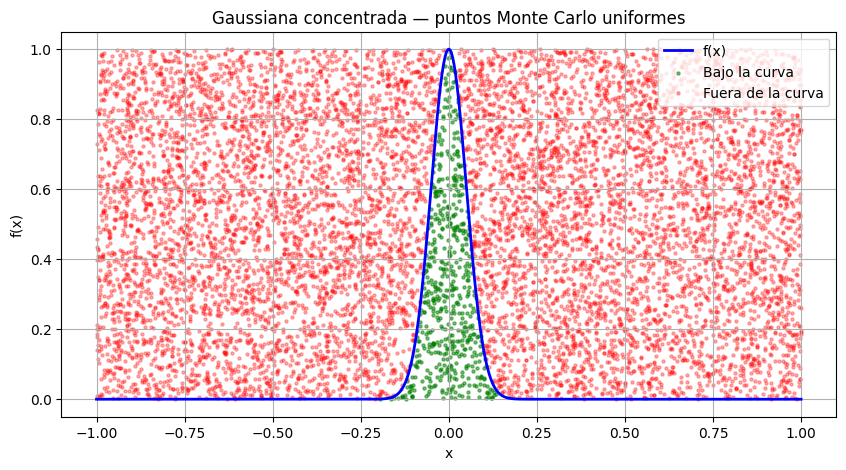

Ejercicio 13: Representación gráfica de la función y los puntos aleatorios
Se generan 10000 puntos aleatorios uniformes en el rectángulo [-1, 1] x [0, 1]
Se puede observar que la mayoría de los puntos caen fuera del pico de la función
lo que significa que el método uniforme es muy ineficiente para funciones con picos estrechos


In [10]:
# EJERCICIO 13
x_plot = np.linspace(a12, b12, 1000)
x_muestra = np.random.uniform(a12, b12, n12)
y_muestra = np.random.uniform(0, M12, n12)
bajo_curva = y_muestra <= f12(x_muestra)

plt.figure(figsize=(10, 5))
plt.plot(x_plot, f12(x_plot), 'b-', label='f(x)', linewidth=2)
plt.scatter(x_muestra[bajo_curva],  y_muestra[bajo_curva],  
            alpha=0.5, s=5, color='green', label='Bajo la curva')
plt.scatter(x_muestra[~bajo_curva], y_muestra[~bajo_curva], 
            alpha=0.3, s=5, color='red',   label='Fuera de la curva')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.title('Gaussiana concentrada — puntos Monte Carlo uniformes')
plt.legend()
plt.grid(True)
plt.show()


print("Ejercicio 13: Representación gráfica de la función y los puntos aleatorios")
print(f"Se generan {n12} puntos aleatorios uniformes en el rectángulo [{a12}, {b12}] x [0, {M12}]")
print("Se puede observar que la mayoría de los puntos caen fuera del pico de la función")
print("lo que significa que el método uniforme es muy ineficiente para funciones con picos estrechos")

---

## Sección 10 — Análisis del Error para el Pico Estrecho (Ej. 14)

Se repite el estudio de convergencia sobre la función con pico estrecho  
para cuantificar la ineficiencia del muestreo uniforme cuando  
la función es casi nula en la mayor parte del dominio.

n=     10: aprox media=0.119847, error medio=0.105024
n=     50: aprox media=0.115476, error medio=0.056502
n=    100: aprox media=0.132772, error medio=0.032472
n=    500: aprox media=0.121615, error medio=0.015713
n=   1000: aprox media=0.124714, error medio=0.011528
n=   5000: aprox media=0.126558, error medio=0.004077
n=  10000: aprox media=0.125308, error medio=0.003290
n=  50000: aprox media=0.124614, error medio=0.001359
n= 100000: aprox media=0.125646, error medio=0.001243
n= 500000: aprox media=0.125305, error medio=0.000447
n=1000000: aprox media=0.125216, error medio=0.000337
n=5000000: aprox media=0.125363, error medio=0.000151


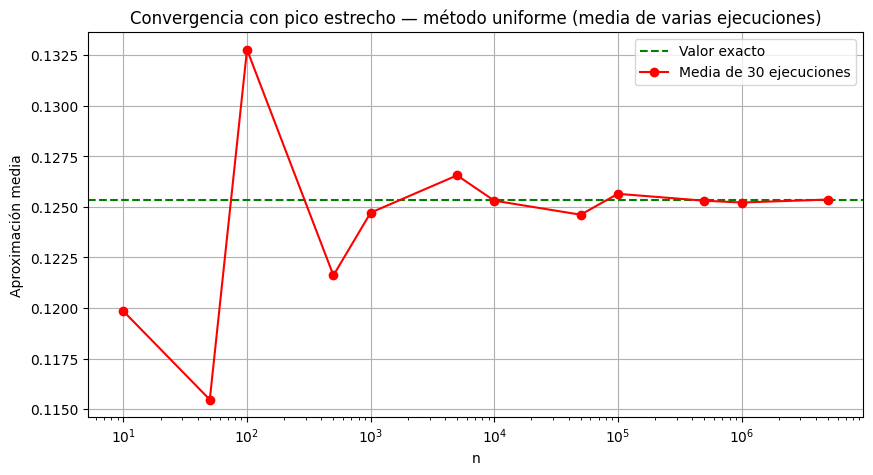


Ejercicio 14: Convergencia del método uniforme con pico estrecho
Valor exacto (en [-1,1]): 0.12533
Se promedian 30 ejecuciones para cada n, lo que suaviza la aleatoriedad.
Se observa que para n pequeño el error medio es muy grande
y que solo para n muy grande empieza a converger al valor exacto,
lo que confirma que el método uniforme es muy ineficiente para funciones con picos estrechos.


In [11]:
# EJERCICIO 14
# Repetimos el experimento varias veces para cada n y usamos el error medio

valores_n14 = sorted(m * 10**i for i in range(1, 7) for m in (1, 5))
errores_medios14 = []
aproximaciones_medias14 = []
n_repeticiones = 30

for n14 in valores_n14:
    resultados = [aproximacion_integral(f12, a12, b12, n14) for _ in range(n_repeticiones)]
    media = np.mean(resultados)
    error_medio = np.mean([abs(r - valor_exacto_12) for r in resultados])
    aproximaciones_medias14.append(media)
    errores_medios14.append(error_medio)
    print(f"n={n14:7d}: aprox media={media:.6f}, error medio={error_medio:.6f}")

plt.figure(figsize=(10, 5))
plt.axhline(y=valor_exacto_12, color='green', linestyle='--', label='Valor exacto')
plt.plot(valores_n14, aproximaciones_medias14, 'o-', color='red', label=f'Media de {n_repeticiones} ejecuciones')
plt.xscale('log')
plt.xlabel('n')
plt.ylabel('Aproximación media')
plt.title('Convergencia con pico estrecho — método uniforme (media de varias ejecuciones)')
plt.legend()
plt.grid(True)
plt.show()

print("\nEjercicio 14: Convergencia del método uniforme con pico estrecho")
print(f"Valor exacto (en [-1,1]): {valor_exacto_12:.5f}")
print(f"Se promedian {n_repeticiones} ejecuciones para cada n, lo que suaviza la aleatoriedad.")
print("Se observa que para n pequeño el error medio es muy grande")
print("y que solo para n muy grande empieza a converger al valor exacto,")
print("lo que confirma que el método uniforme es muy ineficiente para funciones con picos estrechos.")


---

## Sección 11 — Importance Sampling (Ej. 15)

El **importance sampling** reduce la varianza concentrando las muestras donde $f(x)$ es grande:

$$
\int f(x)\,dx = \int \frac{f(x)}{\rho(x)}\,\rho(x)\,dx
\approx \frac{1}{n}\sum_{i=1}^{n}\frac{f(x_i)}{\rho(x_i)}, \quad x_i \sim \rho
$$

Se implementa la función genérica `importance_sampling`.

In [12]:
# EJERCICIO 15 — Importance sampling
# Programa que implementa el método de importance sampling para una densidad rho(x) dada.
# La fórmula es: integral ≈ (1/n) * sum( f(xi) / rho(xi) ) donde xi ~ rho

def importance_sampling(f, rho, generar_muestras, n):

    """
    Aproxima la integral de f usando importance sampling.
    Args:
        f: función a integrar
        rho: densidad de probabilidad usada para el muestreo
        generar_muestras: función que genera n muestras según la densidad rho
        n: número de muestras
    Returns:
        Aproximación de la integral de f
    """

    x = generar_muestras(n)
    return np.mean(f(x) / rho(x))

# Verificación rápida con un caso conocido: ∫₀¹ x² dx = 1/3
# Usamos como densidad rho(x) = 2x en [0,1] (cuya CDF inversa es sqrt(U))
f_test = lambda x: x**2
rho_test = lambda x: 2 * x
gen_test = lambda n: np.sqrt(np.random.uniform(0, 1, n))  # muestras según rho=2x

aprox_is = importance_sampling(f_test, rho_test, gen_test, 100000)
print(f"Verificación importance sampling: ∫₀¹ x² dx")
print(f"Aproximación = {aprox_is:.5f}, exacto = {1/3:.5f}, error = {abs(aprox_is - 1/3):.5f}")


Verificación importance sampling: ∫₀¹ x² dx
Aproximación = 0.33317, exacto = 0.33333, error = 0.00017


---

## Sección 12 — Importance Sampling sobre el Pico Estrecho (Ej. 16)

Se aplica importance sampling a la gaussiana de $\sigma=0.05$,  
usando como densidad de propuesta una gaussiana centrada en el pico.  
Se compara la varianza con el método uniforme.

       n     MC uniforme    err unif   Importance S.      err IS
-----------------------------------------------------------------
      10        0.138366    0.118422        0.125331    0.000000
      50        0.129661    0.034119        0.125331    0.000000
     100        0.121639    0.034393        0.125331    0.000000
     500        0.123397    0.014052        0.125331    0.000000
    1000        0.122292    0.011660        0.125331    0.000000
    5000        0.124743    0.005188        0.125331    0.000000
   10000        0.124331    0.003267        0.125331    0.000000
   50000        0.125175    0.001173        0.125331    0.000000
  100000        0.125365    0.000951        0.125331    0.000000
  500000        0.125377    0.000457        0.125331    0.000000


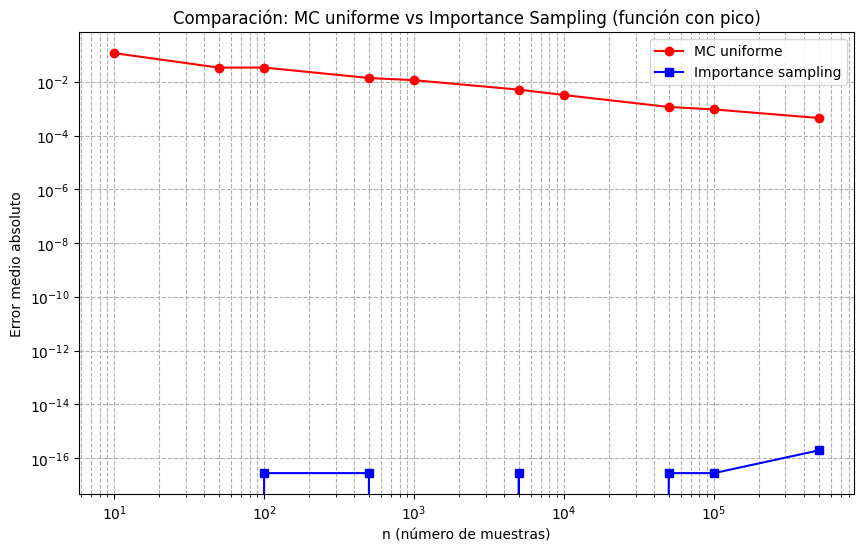


Conclusión: El importance sampling reduce drásticamente el error.
De hecho, el error del IS es prácticamente nulo. Esto se debe a que la densidad
de muestreo elegida (gaussiana con σ=0.05) es proporcional a la propia función f(x),
ya que f(x) = exp(-x²/(2σ²)) y ρ(x) = exp(-x²/(2σ²)) / Z.
Por tanto, el cociente f(x)/ρ(x) = Z (constante), y la varianza del estimador es cero.
Este es el caso ideal del importance sampling: cuando ρ ∝ f, la estimación es exacta.


In [13]:
# EJERCICIO 16 — Importance sampling aplicado a la función con pico estrecho
# Comparación con el método Monte Carlo uniforme

# Función con pico del ejercicio 12: f(x) = exp(-x²/(2σ²)), σ=0.05, en [-1,1]
# Valor exacto en [-1,1]: σ√(2π)·erf(1/(σ√2)) ≈ 0.12533

# Densidad para importance sampling: usamos una gaussiana centrada en 0
# con desviación típica σ_is = 0.05 (similar al pico), truncada en [-1,1]
sigma_is = 0.05

# Constante de normalización de la gaussiana truncada en [-1,1]
Z_is = sigma_is * np.sqrt(2 * np.pi) * (erf(1 / (sigma_is * np.sqrt(2))) )

rho_gauss = lambda x: np.exp(-x**2 / (2 * sigma_is**2)) / Z_is

def generar_gauss_truncada(n):
    """Genera muestras de una gaussiana N(0, sigma_is²) truncada en [-1,1]"""
    muestras = []
    while len(muestras) < n:
        candidatas = np.random.normal(0, sigma_is, n - len(muestras) + 1000)
        validas = candidatas[(candidatas >= a12) & (candidatas <= b12)]
        muestras.extend(validas.tolist())
    return np.array(muestras[:n])

# Comparación para distintos valores de n
valores_n16 = sorted(m * 10**i for i in range(1, 6) for m in (1, 5))

errores_uniforme = []
errores_is = []

print(f"{'n':>8}  {'MC uniforme':>14}  {'err unif':>10}  {'Importance S.':>14}  {'err IS':>10}")
print("-" * 65)

for n16 in valores_n16:
    # Media de 30 ejecuciones para suavizar
    res_unif = [aproximacion_integral(f12, a12, b12, n16) for _ in range(30)]
    res_is   = [importance_sampling(f12, rho_gauss, generar_gauss_truncada, n16) for _ in range(30)]
    
    err_u = np.mean([abs(r - valor_exacto_12) for r in res_unif])
    err_i = np.mean([abs(r - valor_exacto_12) for r in res_is])
    
    errores_uniforme.append(err_u)
    errores_is.append(err_i)
    
    print(f"{n16:8d}  {np.mean(res_unif):14.6f}  {err_u:10.6f}  {np.mean(res_is):14.6f}  {err_i:10.6f}")

# Gráfica comparativa
plt.figure(figsize=(10, 6))
plt.plot(valores_n16, errores_uniforme, 'o-', color='red', label='MC uniforme')
plt.plot(valores_n16, errores_is, 's-', color='blue', label='Importance sampling')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('n (número de muestras)')
plt.ylabel('Error medio absoluto')
plt.title('Comparación: MC uniforme vs Importance Sampling (función con pico)')
plt.legend()
plt.grid(True, which='both', ls='--')
plt.show()

print("\nConclusión: El importance sampling reduce drásticamente el error.")
print("De hecho, el error del IS es prácticamente nulo. Esto se debe a que la densidad")
print("de muestreo elegida (gaussiana con σ=0.05) es proporcional a la propia función f(x),")
print("ya que f(x) = exp(-x²/(2σ²)) y ρ(x) = exp(-x²/(2σ²)) / Z.")
print("Por tanto, el cociente f(x)/ρ(x) = Z (constante), y la varianza del estimador es cero.")
print("Este es el caso ideal del importance sampling: cuando ρ ∝ f, la estimación es exacta.")


---

## Sección 13 — Uniforme vs. Gaussiana: $f(x)=\tfrac{1}{1+x^6}$ en $[-3,3]$ (Ej. 17)

Se compara el Monte Carlo uniforme contra importance sampling  
con diferentes densidades gaussianas $\mathcal{N}(0,\sigma^2)$ para distintos valores de $\sigma$.

Valor exacto (cuadratura): 2.09275004

MC uniforme (n=100000, media de 30 ejec.): 2.092890, error medio = 0.007338

    σ²      σ      Aprox IS      Error IS    Error unif
--------------------------------------------------------
  0.25   0.50      2.091851      0.005898      0.007338
  1.00   1.00      2.092803      0.002384      0.007338
  2.25   1.50      2.092839      0.004670      0.007338
  4.00   2.00      2.092044      0.003687      0.007338
  9.00   3.00      2.090628      0.005144      0.007338


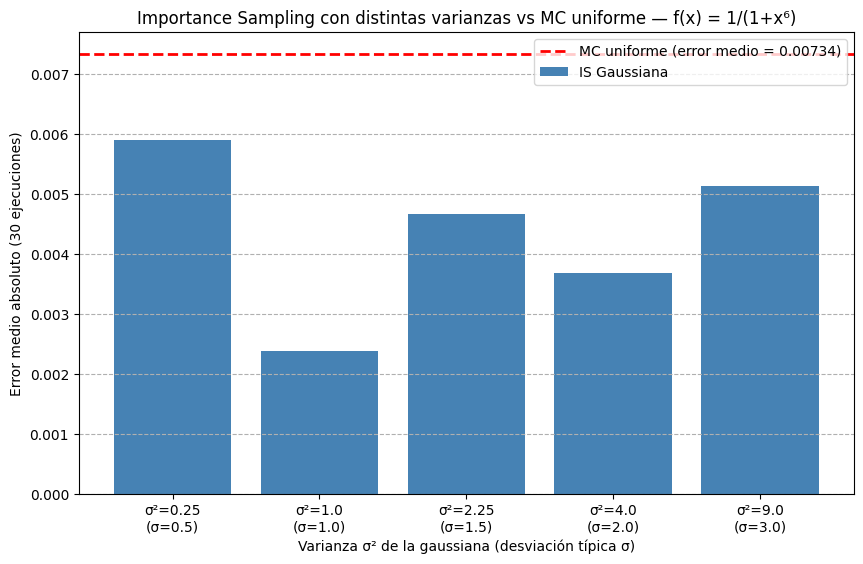


Conclusión: La gaussiana con σ² ≈ 1.0 (σ ≈ 1.0) da los mejores resultados,
ya que se adapta bien a la forma de f(x) = 1/(1+x⁶), que tiene la mayor
parte de su área concentrada alrededor de x=0 pero con colas moderadas.
σ² muy pequeña concentra demasiado las muestras y desaprovecha las colas,
mientras que σ² muy grande dispersa las muestras y se comporta como la uniforme.


In [14]:
# EJERCICIO 17 — f(x) = 1/(1+x⁶) en [-3,3], uniforme vs gaussiana con distintas varianzas

f17 = lambda x: 1 / (1 + x**6)
a17, b17 = -3, 3

# Valor exacto (referencia numérica)
valor_exacto_17, _ = quad(f17, a17, b17)
print(f"Valor exacto (cuadratura): {valor_exacto_17:.8f}\n")

# --- Método uniforme (media de 30 ejecuciones) ---
n17 = 100000
res_unif_17 = [aproximacion_integral(f17, a17, b17, n17) for _ in range(30)]
err_unif_medio = np.mean([abs(r - valor_exacto_17) for r in res_unif_17])
print(f"MC uniforme (n={n17}, media de 30 ejec.): {np.mean(res_unif_17):.6f}, error medio = {err_unif_medio:.6f}")

# --- Importance sampling con gaussiana N(0, σ²) truncada en [-3,3] ---
# El enunciado pide probar distintos valores de la varianza σ².
# Usamos las siguientes varianzas (y sus desviaciones típicas correspondientes):
varianzas_17 = [0.25, 1.0, 2.25, 4.0, 9.0]  # σ² = 0.25, 1, 2.25, 4, 9
sigmas_17 = [np.sqrt(v) for v in varianzas_17]  # σ = 0.5, 1.0, 1.5, 2.0, 3.0

print(f"\n{'σ²':>6}  {'σ':>5}  {'Aprox IS':>12}  {'Error IS':>12}  {'Error unif':>12}")
print("-" * 56)

errores_sigma = []

for var17, sig in zip(varianzas_17, sigmas_17):
    # Constante de normalización de la gaussiana truncada en [-3,3]
    Z17 = norm.cdf(b17, 0, sig) - norm.cdf(a17, 0, sig)
    
    rho17 = lambda x, s=sig, z=Z17: norm.pdf(x, 0, s) / z
    
    def gen_gauss17(n, s=sig):
        muestras = []
        while len(muestras) < n:
            candidatas = np.random.normal(0, s, n - len(muestras) + 2000)
            validas = candidatas[(candidatas >= a17) & (candidatas <= b17)]
            muestras.extend(validas.tolist())
        return np.array(muestras[:n])
    
    # Media de 30 ejecuciones
    res_is17 = [importance_sampling(f17, rho17, gen_gauss17, n17) for _ in range(30)]
    media_is = np.mean(res_is17)
    err_is = np.mean([abs(r - valor_exacto_17) for r in res_is17])
    errores_sigma.append(err_is)
    
    print(f"{var17:6.2f}  {sig:5.2f}  {media_is:12.6f}  {err_is:12.6f}  {err_unif_medio:12.6f}")

# Gráfica
plt.figure(figsize=(10, 6))
etiquetas = [f"σ²={v}\n(σ={s:.1f})" for v, s in zip(varianzas_17, sigmas_17)]
plt.bar(etiquetas, errores_sigma, color='steelblue', label='IS Gaussiana')
plt.axhline(y=err_unif_medio, color='red', linestyle='--', linewidth=2,
            label=f'MC uniforme (error medio = {err_unif_medio:.5f})')
plt.xlabel('Varianza σ² de la gaussiana (desviación típica σ)')
plt.ylabel('Error medio absoluto (30 ejecuciones)')
plt.title('Importance Sampling con distintas varianzas vs MC uniforme — f(x) = 1/(1+x⁶)')
plt.legend()
plt.grid(True, axis='y', ls='--')
plt.show()

print("\nConclusión: La gaussiana con σ² ≈ 1.0 (σ ≈ 1.0) da los mejores resultados,")
print("ya que se adapta bien a la forma de f(x) = 1/(1+x⁶), que tiene la mayor")
print("parte de su área concentrada alrededor de x=0 pero con colas moderadas.")
print("σ² muy pequeña concentra demasiado las muestras y desaprovecha las colas,")
print("mientras que σ² muy grande dispersa las muestras y se comporta como la uniforme.")


---

## Sección 14 — Monte Carlo vs. Regla del Rectángulo (Ej. 18)

Se compara el error de ambos métodos en función de *n*:

| Método | Orden de convergencia |
|--------|----------------------|
| Monte Carlo | $O(n^{-1/2})$ |
| Rectángulo compuesto | $O(n^{-1})$ |


       n      Error MC   Error Rect.
------------------------------------
      10    0.10725715    0.08448243
      50    0.03885884    0.01712554
     100    0.04206377    0.00857709
     500    0.01634459    0.00171771
    1000    0.01177446    0.00085900
    5000    0.00511620    0.00017182
   10000    0.00401982    0.00008591
   50000    0.00185099    0.00001718
  100000    0.00153750    0.00000859
  500000    0.00067549    0.00000172


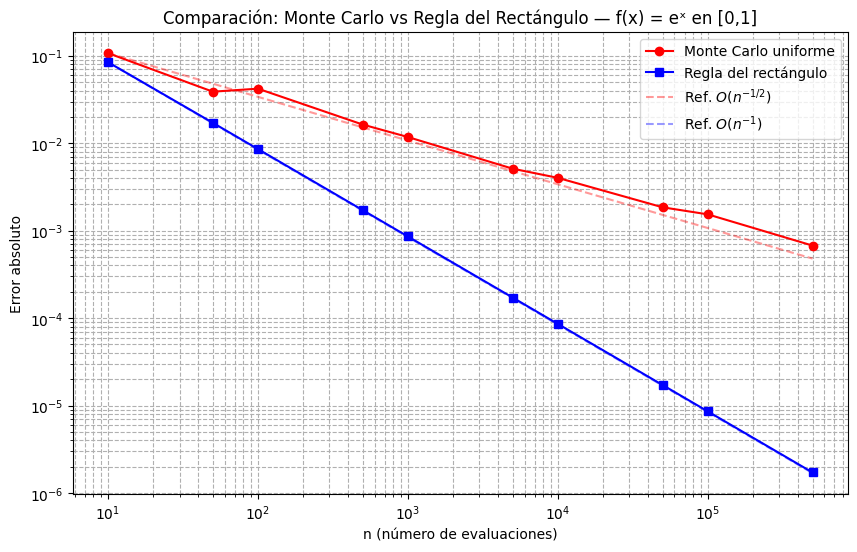


Conclusión: La regla del rectángulo, con un orden de convergencia O(n⁻¹),
converge más rápido que Monte Carlo, cuyo orden es O(n⁻¹/²).
En dimensión 1, los métodos deterministas son claramente superiores.
Sin embargo, en dimensiones altas, MC mantiene O(n⁻¹/²) independientemente de la dimensión,
mientras que los métodos deterministas sufren la 'maldición de la dimensionalidad'.


In [15]:
# EJERCICIO 18 — Comparación Monte Carlo uniforme vs regla del rectángulo

def regla_rectangulo(f, a, b, n):
    """
    Aproxima la integral de f en [a,b] usando la regla del rectángulo compuesta.
    Se evalúa f en el extremo izquierdo de cada subintervalo:
    ∫f dx ≈ h * Σ f(xᵢ), con xᵢ = a + i*h, i = 0, ..., n-1.
    """
    h = (b - a) / n
    x = np.linspace(a, a + (n - 1) * h, n)  # extremos izquierdos
    return h * np.sum(f(x))

# Función de prueba: f(x) = e^x en [0, 1], valor exacto = e - 1
f18 = lambda x: np.exp(x)
a18, b18 = 0, 1
valor_exacto_18 = np.e - 1

valores_n18 = sorted(m * 10**i for i in range(1, 6) for m in (1, 5))

errores_mc18 = []
errores_rect18 = []

print(f"{'n':>8}  {'Error MC':>12}  {'Error Rect.':>12}")
print("-" * 36)

for n18 in valores_n18:
    # MC: media de 30 ejecuciones
    res_mc = [aproximacion_integral(f18, a18, b18, n18) for _ in range(30)]
    err_mc = np.mean([abs(r - valor_exacto_18) for r in res_mc])
    
    # Regla del rectángulo (determinista)
    aprox_rect = regla_rectangulo(f18, a18, b18, n18)
    err_rect = abs(aprox_rect - valor_exacto_18)
    
    errores_mc18.append(err_mc)
    errores_rect18.append(err_rect)
    
    print(f"{n18:8d}  {err_mc:12.8f}  {err_rect:12.8f}")

# Gráfica comparativa
plt.figure(figsize=(10, 6))
plt.plot(valores_n18, errores_mc18, 'o-', color='red', label='Monte Carlo uniforme')
plt.plot(valores_n18, errores_rect18, 's-', color='blue', label='Regla del rectángulo')

# Líneas de referencia
ref_mc   = [errores_mc18[0] * (valores_n18[0]/n)**0.5 for n in valores_n18]
ref_rect = [errores_rect18[0] * (valores_n18[0]/n)**1 for n in valores_n18]
plt.plot(valores_n18, ref_mc,   '--', color='red', alpha=0.4, label=r'Ref. $O(n^{-1/2})$')
plt.plot(valores_n18, ref_rect, '--', color='blue', alpha=0.4, label=r'Ref. $O(n^{-1})$')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('n (número de evaluaciones)')
plt.ylabel('Error absoluto')
plt.title('Comparación: Monte Carlo vs Regla del Rectángulo — f(x) = eˣ en [0,1]')
plt.legend()
plt.grid(True, which='both', ls='--')
plt.show()

print("\nConclusión: La regla del rectángulo, con un orden de convergencia O(n⁻¹),")
print("converge más rápido que Monte Carlo, cuyo orden es O(n⁻¹/²).")
print("En dimensión 1, los métodos deterministas son claramente superiores.")
print("Sin embargo, en dimensiones altas, MC mantiene O(n⁻¹/²) independientemente de la dimensión,")
print("mientras que los métodos deterministas sufren la 'maldición de la dimensionalidad'.")


---

## Sección 15 — Monte Carlo para Integrales Dobles (Ej. 19)

Extensión del método a dominios bidimensionales:

$$
\iint_D f(x,y)\,dx\,dy \approx \operatorname{vol}(D)\cdot\frac{1}{n}\sum_{i=1}^{n}f(x_i,y_i),
\quad (x_i,y_i)\sim\mathcal{U}(D)
$$

In [16]:
# EJERCICIO 19 — Monte Carlo para integral doble en dominio rectangular
# Fórmula: ∫∫_D f(x,y) dxdy ≈ vol(D) * (1/n) * Σ f(xᵢ, yᵢ)
# donde (xᵢ, yᵢ) son puntos aleatorios uniformes en D = [ax,bx] × [ay,by]

def mc_integral_2d(f, ax, bx, ay, by, n):
    """
    Aproxima la integral doble de f en el rectángulo [ax,bx] × [ay,by]
    usando el método Monte Carlo con n puntos aleatorios.
    
    Parámetros:
        f       : función de dos variables f(x, y)
        ax, bx  : extremos del intervalo en x
        ay, by  : extremos del intervalo en y
        n       : número de muestras
    Devuelve:
        Aproximación de la integral doble
    """
    area = (bx - ax) * (by - ay)
    x = np.random.uniform(ax, bx, n)
    y = np.random.uniform(ay, by, n)
    return area * np.mean(f(x, y))

print("Ejercicio 19: Método Monte Carlo para integrales dobles implementado.")
print("Función mc_integral_2d(f, ax, bx, ay, by, n) disponible.")


Ejercicio 19: Método Monte Carlo para integrales dobles implementado.
Función mc_integral_2d(f, ax, bx, ay, by, n) disponible.


---

## Sección 16 — Aplicaciones del MC 2D (Ej. 20)

Se valida el método 2D sobre funciones con valor exacto conocido  
y se comparan los resultados con `scipy.integrate.dblquad`.

Aproximaciones Monte Carlo 2D (n=100000, media de 30 ejecuciones)

Función            Dominio            Aprox MC     Exacto  Error medio
----------------------------------------------------------------------
x² + y²            [0,1]×[0,1]        0.666951   0.666667     0.001300
sin(x)cos(y)       [0,π]×[0,π/2]      1.999777   2.000000     0.003625
exp(-(x²+y²))      [-1,1]×[-1,1]      2.232533   2.230985     0.002291


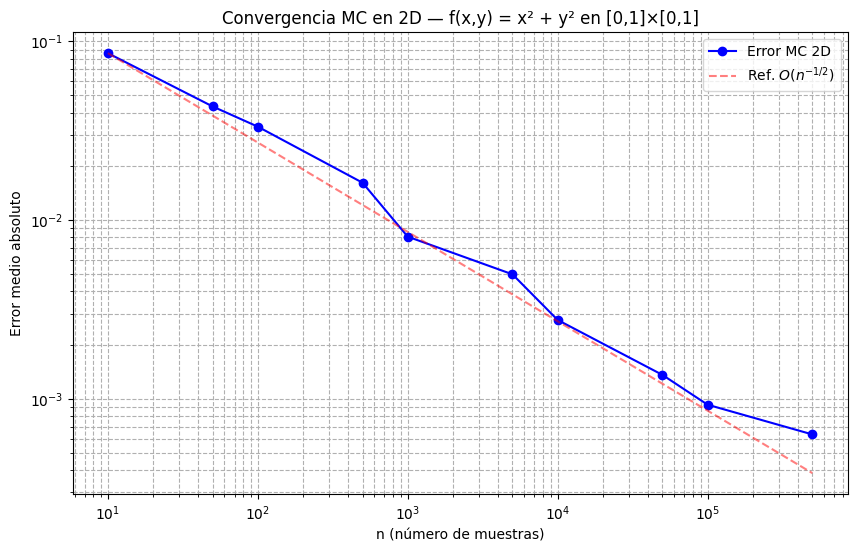


Conclusión: El método Monte Carlo se extiende de forma natural a 2D.
El orden de convergencia sigue siendo O(n⁻¹/²), igual que en 1D,
lo que es una de las grandes ventajas de MC en dimensión alta.


In [17]:
# EJERCICIO 20 — Aplicar el método MC 2D a funciones sencillas con valor exacto conocido


# Función 1: f(x,y) = x² + y² en [0,1] × [0,1]
# Valor exacto: ∫₀¹∫₀¹ (x² + y²) dxdy = 1/3 + 1/3 = 2/3
f20a = lambda x, y: x**2 + y**2
exacto_20a = 2/3

# Función 2: f(x,y) = sin(x) * cos(y) en [0,π] × [0,π/2]
# Valor exacto: ∫₀^π sin(x)dx * ∫₀^{π/2} cos(y)dy = 2 * 1 = 2
f20b = lambda x, y: np.sin(x) * np.cos(y)
exacto_20b = 2.0

# Función 3: f(x,y) = exp(-(x² + y²)) en [-1,1] × [-1,1]
# Valor exacto calculado numéricamente
f20c = lambda x, y: np.exp(-(x**2 + y**2))
exacto_20c, _ = dblquad(lambda y, x: np.exp(-(x**2 + y**2)), -1, 1, -1, 1)

funciones_2d = [
    (f20a, 0, 1, 0, 1, exacto_20a, "x² + y²", "[0,1]×[0,1]"),
    (f20b, 0, np.pi, 0, np.pi/2, exacto_20b, "sin(x)cos(y)", "[0,π]×[0,π/2]"),
    (f20c, -1, 1, -1, 1, exacto_20c, "exp(-(x²+y²))", "[-1,1]×[-1,1]"),
]

n20 = 100000
n_rep = 30

print(f"Aproximaciones Monte Carlo 2D (n={n20}, media de {n_rep} ejecuciones)\n")
print(f"{'Función':<18} {'Dominio':<16} {'Aprox MC':>10} {'Exacto':>10} {'Error medio':>12}")
print("-" * 70)

for f_2d, ax, bx, ay, by, exacto, nombre, dominio in funciones_2d:
    resultados = [mc_integral_2d(f_2d, ax, bx, ay, by, n20) for _ in range(n_rep)]
    media = np.mean(resultados)
    error_medio = np.mean([abs(r - exacto) for r in resultados])
    print(f"{nombre:<18} {dominio:<16} {media:10.6f} {exacto:10.6f} {error_medio:12.6f}")

# Estudio de convergencia para f(x,y) = x² + y²
valores_n20 = sorted(m * 10**i for i in range(1, 6) for m in (1, 5))
errores_2d = []

for n_val in valores_n20:
    res = [mc_integral_2d(f20a, 0, 1, 0, 1, n_val) for _ in range(n_rep)]
    errores_2d.append(np.mean([abs(r - exacto_20a) for r in res]))

plt.figure(figsize=(10, 6))
plt.plot(valores_n20, errores_2d, 'o-', color='blue', label='Error MC 2D')
ref_2d = [errores_2d[0] * (valores_n20[0]/n)**0.5 for n in valores_n20]
plt.plot(valores_n20, ref_2d, '--', color='red', alpha=0.5, label=r'Ref. $O(n^{-1/2})$')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('n (número de muestras)')
plt.ylabel('Error medio absoluto')
plt.title('Convergencia MC en 2D — f(x,y) = x² + y² en [0,1]×[0,1]')
plt.legend()
plt.grid(True, which='both', ls='--')
plt.show()

print("\nConclusión: El método Monte Carlo se extiende de forma natural a 2D.")
print("El orden de convergencia sigue siendo O(n⁻¹/²), igual que en 1D,")
print("lo que es una de las grandes ventajas de MC en dimensión alta.")


---

## Sección 17 — MC en Dominio No Rectangular: Disco (Ej. 21)

Se generan puntos en un rectángulo que contiene el disco $D = \{(x,y): x^2+y^2 \leq r^2\}$
y se aceptan solo los que caen dentro del dominio:

$$\iint_D f(x,y)\,dx\,dy \approx \operatorname{vol}(D)\cdot\frac{1}{n_{\mathrm{ac}}}\sum_{i:\,x_i^2+y_i^2\leq r^2}f(x_i,y_i)$$

donde $\operatorname{vol}(D)=\pi r^2$.

Monte Carlo en disco (r=1.0, n=200000, media de 30 ejecuciones)

Funcion                     Aprox MC     Exacto      Error
----------------------------------------------------------
f=1 (area del disco)        3.141593   3.141593   0.000000
f=x^2+y^2                   1.571295   1.570796   0.000499


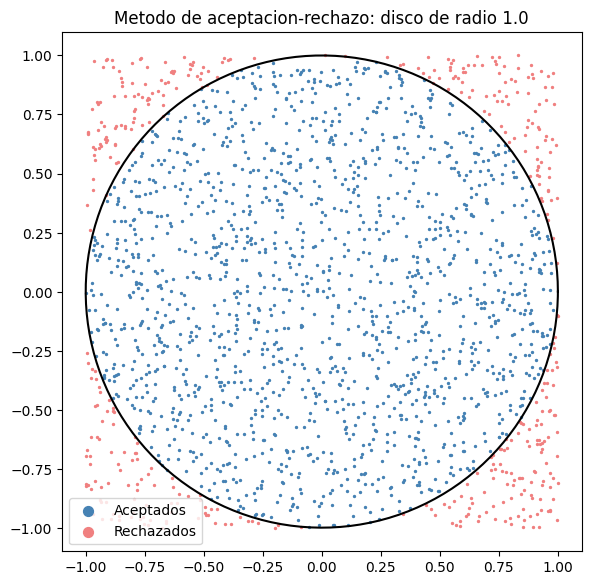


Proporcion de puntos aceptados: 0.7855  (pi/4 = 0.7854, estimacion de pi = 3.1420)


In [18]:
# EJERCICIO 21 — MC en dominio no rectangular (disco)
# Genera n puntos uniformes en [-r,r]x[-r,r] y acepta los que estan en el disco.

def mc_integral_disco(f, r, n):
    # Aproxima la integral de f sobre el disco de radio r.
    # Metodo: aceptacion-rechazo dentro del cuadrado [-r,r]^2.
    x = np.random.uniform(-r, r, n)
    y = np.random.uniform(-r, r, n)
    dentro = x**2 + y**2 <= r**2
    vol_disco = np.pi * r**2
    return vol_disco * np.mean(f(x[dentro], y[dentro]))

# Prueba 1: f=1 => integral = area del disco = pi*r^2
r21 = 1.0
f21a = lambda x, y: np.ones_like(x)
exacto_21a = np.pi * r21**2

# Prueba 2: f(x,y)=x^2+y^2 en disco radio 1
# Exacto: integral_0^{2pi} integral_0^1 rho^2 * rho d rho d theta = 2*pi*(1/4) = pi/2
f21b = lambda x, y: x**2 + y**2
exacto_21b = np.pi / 2

funciones_disco = [
    (f21a, "f=1 (area del disco)", exacto_21a),
    (f21b, "f=x^2+y^2",           exacto_21b),
]

n21 = 200_000
n_rep21 = 30

print(f"Monte Carlo en disco (r={r21}, n={n21}, media de {n_rep21} ejecuciones)\n")
print(f"{'Funcion':<25} {'Aprox MC':>10} {'Exacto':>10} {'Error':>10}")
print("-" * 58)
for f_d, nombre, exacto in funciones_disco:
    resultados = [mc_integral_disco(f_d, r21, n21) for _ in range(n_rep21)]
    media = np.mean(resultados)
    error = abs(media - exacto)
    print(f"{nombre:<25} {media:10.6f} {exacto:10.6f} {error:10.6f}")

# Visualizacion: puntos aceptados/rechazados
np.random.seed(SEED)   # misma semilla para la visualización
x_vis = np.random.uniform(-r21, r21, 2000)
y_vis = np.random.uniform(-r21, r21, 2000)
dentro_vis = x_vis**2 + y_vis**2 <= r21**2

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(x_vis[ dentro_vis], y_vis[ dentro_vis], s=2, color='steelblue', label='Aceptados')
ax.scatter(x_vis[~dentro_vis], y_vis[~dentro_vis], s=2, color='lightcoral', label='Rechazados')
theta = np.linspace(0, 2*np.pi, 300)
ax.plot(np.cos(theta), np.sin(theta), 'k-', lw=1.5)
ax.set_aspect('equal')
ax.set_title(f'Metodo de aceptacion-rechazo: disco de radio {r21}')
ax.legend(markerscale=5)
plt.tight_layout()
plt.show()

p_ac = np.mean(dentro_vis)
print(f"\nProporcion de puntos aceptados: {p_ac:.4f}  "
      f"(pi/4 = {np.pi/4:.4f}, estimacion de pi = {4*p_ac:.4f})")


---

## Sección 18 — Método Determinista en Malla Rectangular (Ej. 22)

Se aproxima la misma integral sobre el disco con la **regla del rectángulo 2D**: evaluar $f$ en los nodos de una malla $m\times m$ sobre $[-r,r]^2$ y sumar solo los puntos dentro del disco:

$$\iint_D f\,dx\,dy \approx h^2\sum_{\substack{i,j \\ x_i^2+y_j^2\leq r^2}} f(x_i,y_j), \quad h = \frac{2r}{m}$$

Se compara el número de evaluaciones de $f$ necesarias para alcanzar una precisión similar en ambos métodos.

Regla del rectangulo 2D en el disco (f=x^2+y^2, exacto=pi/2)

     m    n_eval       Aprox       Error
----------------------------------------
    10        80    1.625600    0.054804
    20       316    1.588600    0.017804
    50      1976    1.590712    0.019916
   100      7860    1.573180    0.002384
   200     31428    1.572002    0.001206
   500    196364    1.571027    0.000231

Monte Carlo en el disco (f=x^2+y^2, exacto=pi/2)

       n   Error medio
------------------------
     100      0.077702
     400      0.043126
    2500      0.019016
   10000      0.006788
   40000      0.003933
  250000      0.001868


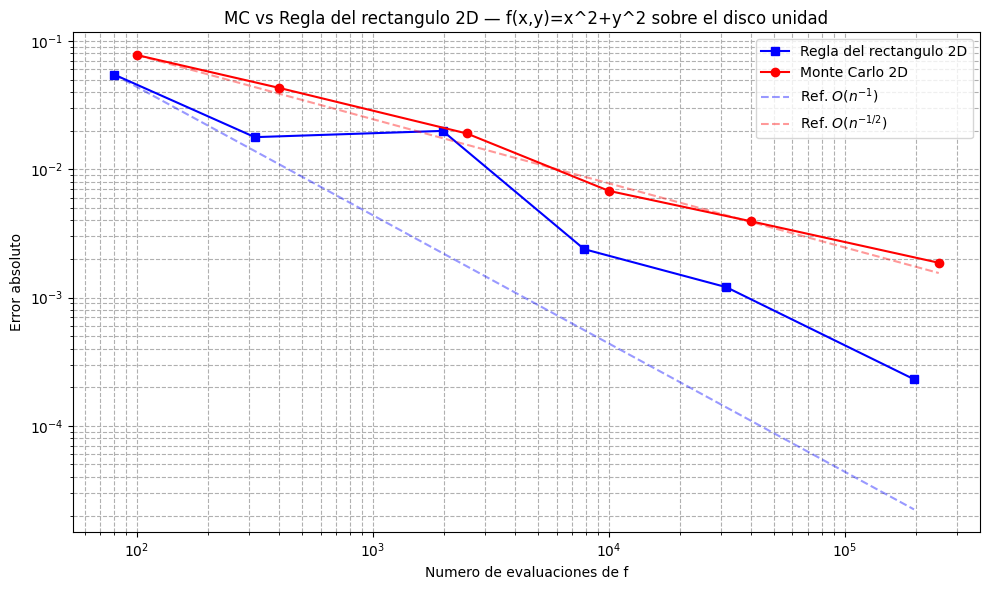


Pendiente ajustada (log error vs log n): rectángulo 2D = -0.69, Monte Carlo = -0.49

Conclusión: sobre el disco, la regla del rectángulo 2D NO alcanza el orden O(n^{-1}) que tenía en 1D.
El error no decrece de forma monótona (con m=50 es mayor que con m=20) y la pendiente ajustada
queda entre -1/2 y -1. El motivo es el borde curvo: la malla lo aproxima con un escalonado, lo que
introduce un error del orden del paso h = 2r/m, es decir, de orden n^{-1/2} en el número de nodos.
Aun así, salvo para m = 50, la malla obtiene en este ejemplo errores menores que MC con un número de evaluaciones similar.
Al aumentar la dimensión, sin embargo, la malla crece exponencialmente (maldición de la dimensionalidad), mientras que MC no.


In [19]:
# EJERCICIO 22 — Regla del rectangulo 2D en el disco y comparacion con MC

def rect_integral_disco(f, r, m):
    # Aproxima la integral de f sobre el disco (radio r) con la regla del
    # rectangulo 2D: malla m x m de centros en [-r,r]^2, solo puntos en el disco.
    # Devuelve (aproximacion, numero de evaluaciones de f usadas).
    h = 2 * r / m
    coords = np.linspace(-r + h/2, r - h/2, m)
    X, Y = np.meshgrid(coords, coords)
    dentro = X**2 + Y**2 <= r**2
    n_eval = int(np.sum(dentro))
    integral = h**2 * np.sum(f(X[dentro], Y[dentro]))
    return integral, n_eval

r22 = 1.0
f22 = lambda x, y: x**2 + y**2   # exacto = pi/2
exacto_22 = np.pi / 2

# Barrido de m (metodo determinista)
valores_m = [10, 20, 50, 100, 200, 500]
print("Regla del rectangulo 2D en el disco (f=x^2+y^2, exacto=pi/2)\n")
print(f"{'m':>6}  {'n_eval':>8}  {'Aprox':>10}  {'Error':>10}")
print("-" * 40)
errores_rect22 = []
n_eval_rect22 = []
for m in valores_m:
    aprox, n_eval = rect_integral_disco(f22, r22, m)
    err = abs(aprox - exacto_22)
    errores_rect22.append(err)
    n_eval_rect22.append(n_eval)
    print(f"{m:6d}  {n_eval:8d}  {aprox:10.6f}  {err:10.6f}")

# Barrido de n (Monte Carlo)
valores_n22 = [100, 400, 2500, 10000, 40000, 250000]
n_rep22 = 50
print("\nMonte Carlo en el disco (f=x^2+y^2, exacto=pi/2)\n")
print(f"{'n':>8}  {'Error medio':>12}")
print("-" * 24)
errores_mc22 = []
for n22 in valores_n22:
    res = [mc_integral_disco(f22, r22, n22) for _ in range(n_rep22)]
    err = np.mean([abs(r - exacto_22) for r in res])
    errores_mc22.append(err)
    print(f"{n22:8d}  {err:12.6f}")

# Grafica comparativa
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(n_eval_rect22, errores_rect22, 's-', color='blue', label='Regla del rectangulo 2D')
ax.plot(valores_n22,   errores_mc22,   'o-', color='red',  label='Monte Carlo 2D')

ref_rect = [errores_rect22[0] * (n_eval_rect22[0]/n) for n in n_eval_rect22]
ref_mc   = [errores_mc22[0]   * (valores_n22[0]/n)**0.5 for n in valores_n22]
ax.plot(n_eval_rect22, ref_rect, '--', color='blue', alpha=0.4, label=r'Ref. $O(n^{-1})$')
ax.plot(valores_n22,   ref_mc,   '--', color='red',  alpha=0.4, label=r'Ref. $O(n^{-1/2})$')

ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('Numero de evaluaciones de f')
ax.set_ylabel('Error absoluto')
ax.set_title('MC vs Regla del rectangulo 2D — f(x,y)=x^2+y^2 sobre el disco unidad')
ax.legend(); ax.grid(True, which='both', ls='--')
plt.tight_layout()
plt.show()

# Orden empírico de la regla del rectángulo 2D: pendiente de la recta ajustada en log-log
pendiente_rect22 = np.polyfit(np.log(n_eval_rect22), np.log(errores_rect22), 1)[0]
pendiente_mc22   = np.polyfit(np.log(valores_n22),   np.log(errores_mc22),   1)[0]
print(f"\nPendiente ajustada (log error vs log n): rectángulo 2D = {pendiente_rect22:.2f}, Monte Carlo = {pendiente_mc22:.2f}")

print("\nConclusión: sobre el disco, la regla del rectángulo 2D NO alcanza el orden O(n^{-1}) que tenía en 1D.")
print("El error no decrece de forma monótona (con m=50 es mayor que con m=20) y la pendiente ajustada")
print("queda entre -1/2 y -1. El motivo es el borde curvo: la malla lo aproxima con un escalonado, lo que")
print("introduce un error del orden del paso h = 2r/m, es decir, de orden n^{-1/2} en el número de nodos.")
# Comparación con un número de evaluaciones similar (para cada malla, el n de MC más próximo)
peores = []
for m_, ne, er in zip(valores_m, n_eval_rect22, errores_rect22):
    j = int(np.argmin([abs(np.log(nm) - np.log(ne)) for nm in valores_n22]))
    if errores_mc22[j] < er:
        peores.append(m_)
if peores:
    print(f"Aun así, salvo para m = {', '.join(map(str, peores))}, la malla obtiene en este ejemplo errores menores que MC con un número de evaluaciones similar.")
else:
    print("Aun así, en este ejemplo la malla obtiene errores menores que MC con un número de evaluaciones similar.")
print("Al aumentar la dimensión, sin embargo, la malla crece exponencialmente (maldición de la dimensionalidad), mientras que MC no.")


---

## Sección 19 — MC en Dimensión Alta (Ej. 23)

Se aproxima la integral

$$I_d = \int_{[-1,1]^d} \frac{1}{1+\|\boldsymbol{x}\|_2^8}\,d\boldsymbol{x},\qquad \|\boldsymbol{x}\|_2 = \sqrt{x_1^2+\cdots+x_d^2}$$

mediante Monte Carlo. El volumen del hipercubo $[-1,1]^d$ es $2^d$.

In [20]:


def mc_integral_dim_d(d, n):
    # Aproxima la integral de 1/(1+||x||_2^8) en el hipercubo [-1,1]^d
    # mediante Monte Carlo con n puntos aleatorios uniformes.
    X = np.random.uniform(-1, 1, size=(n, d))   # n puntos en [-1,1]^d  (n x d)
    norma2_8 = np.sum(X**2, axis=1)**4           # ||x||_2^8 = (||x||_2^2)^4
    f_vals = 1.0 / (1.0 + norma2_8)
    vol = 2.0**d                                 # vol([-1,1]^d) = 2^d
    return vol * np.mean(f_vals)

# Verificacion en d=1: valor exacto con scipy
from scipy.integrate import quad
exacto_d1, _ = quad(lambda x: 1 / (1 + x**8), -1, 1)

n_test = 500_000
aprox_d1_mc = mc_integral_dim_d(1, n_test)
print(f"d=1: exacto = {exacto_d1:.6f},  MC (n={n_test}) = {aprox_d1_mc:.6f},  "
      f"error = {abs(aprox_d1_mc - exacto_d1):.2e}")

# Aproximaciones para d = 1, 2, 3, 5, 10
dims = [1, 2, 3, 5, 10]
n23 = 500_000
n_rep23 = 20

print(f"\nAproximaciones MC (n={n23}, media de {n_rep23} ejecuciones)\n")
print(f"{'d':>4}  {'Aprox MC':>12}  {'Desv. tipica':>14}")
print("-" * 34)

resultados_dims = {}
for d in dims:
    res = [mc_integral_dim_d(d, n23) for _ in range(n_rep23)]
    media = np.mean(res)
    std   = np.std(res)
    resultados_dims[d] = (media, std)
    print(f"{d:4d}  {media:12.6f}  {std:14.6f}")

# Valor medio de f en el hipercubo: integral / volumen
print(f"\n{'d':>4}  {'Volumen 2^d':>12}  {'Media de f':>11}  {'Desv./media':>12}")
print("-" * 46)
for d in dims:
    media, std = resultados_dims[d]
    print(f"{d:4d}  {2**d:12d}  {media / 2**d:11.4f}  {std / media:12.2e}")

print("\nNota: f(x) = 1/(1+||x||^8) vale casi 1 cerca del origen y tiende a 0 lejos de él.")
print("En dimensión alta, casi todo el volumen del hipercubo [-1,1]^d está lejos del origen,")
print("por lo que el valor medio de f disminuye con d. La integral crece igualmente porque el")
print("volumen 2^d aumenta más rápido de lo que disminuye ese valor medio.")
print("\nLa desviación típica también crece con d aunque n sea fijo: el error de MC es")
print("aproximadamente desv(vol·f(X))/sqrt(n). El orden n^{-1/2} no depende de d, pero la constante sí.")
print("Aquí f es casi nula salvo en una región cada vez más pequeña (relativamente) en torno al origen,")
print("así que la varianza de vol·f(X) aumenta, y con ella el error relativo.")


d=1: exacto = 1.849303,  MC (n=500000) = 1.849680,  error = 3.76e-04

Aproximaciones MC (n=500000, media de 20 ejecuciones)

   d      Aprox MC    Desv. tipica
----------------------------------
   1      1.849296        0.000433
   2      2.984461        0.001464
   3      4.352186        0.002972
   5      7.633527        0.010513
  10     22.652040        0.048408

   d   Volumen 2^d   Media de f   Desv./media
----------------------------------------------
   1             2       0.9246      2.34e-04
   2             4       0.7461      4.91e-04
   3             8       0.5440      6.83e-04
   5            32       0.2385      1.38e-03
  10          1024       0.0221      2.14e-03

Nota: f(x) = 1/(1+||x||^8) vale casi 1 cerca del origen y tiende a 0 lejos de él.
En dimensión alta, casi todo el volumen del hipercubo [-1,1]^d está lejos del origen,
por lo que el valor medio de f disminuye con d. La integral crece igualmente porque el
volumen 2^d aumenta más rápido de lo que disminuye

---

## Sección 20 — Coste Computacional en Dimensión Alta (Ej. 24)

Se compara, para cada dimensión $d$, el número de evaluaciones de $f$ y el tiempo
necesarios para el método MC (fijo en $n$) y para la malla regular con $m$ nodos
por dirección (total $m^d$ evaluaciones).

| Método | Evaluaciones | Coste crece con $d$ |
|--------|-------------|---------------------|
| MC | $n$ (fijo) | No |
| Malla regular | $m^d$ | Exponencialmente |

   d      n_MC    t_MC (s)    n_malla=m^d   t_malla (s)
   1    100000      0.0042             10        0.0002
   2    100000      0.0045            100        0.0001
   3    100000      0.0045           1000        0.0002
   5    100000      0.0060         100000        0.0073
  10    100000      0.0112    10000000000           N/A

Con m=10 nodos/dir., la malla tiene m^d nodos.
Para d=10: m^d = 1.00e+10 => inabordable. MC siempre usa n=100000.



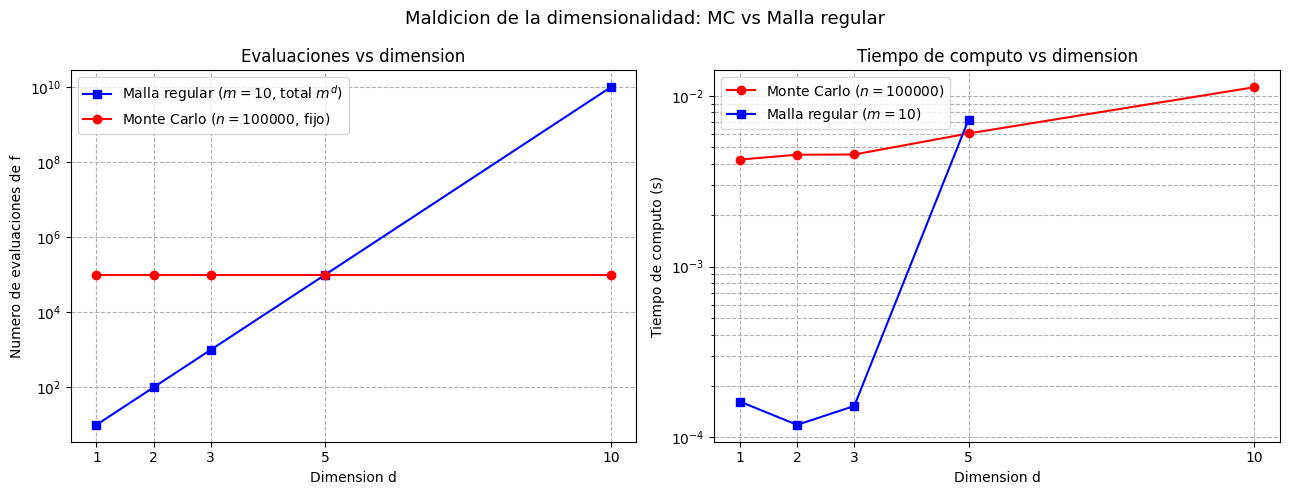

Aproximaciones de ambos metodos para d = 1, 2, 3, 5  (m=10, n=100 000):

   d      Aprox MC    Aprox Malla    Ref. (d=1)
------------------------------------------------
   1      1.849286       1.856244      1.849303
   2      2.989480       3.001069             —
   3      4.343204       4.381030             —
   5      7.651660       7.697142             —

Conclusion:
  La malla regular requiere m^d evaluaciones: crecimiento EXPONENCIAL en d.
  Con m=10 y d=10 necesitaria ~10 000 millones de evaluaciones.
  Monte Carlo usa siempre n evaluaciones y su error es O(n^{-1/2}): el ORDEN no depende
  de la dimension d, aunque la constante (la varianza de f) si puede crecer con d (ejercicio 23).
  En dimension alta, MC es la unica opcion computacionalmente viable.
  Esta es la razon fundamental de su uso en Machine Learning y simulacion.


In [21]:


dims   = [1, 2, 3, 5, 10]
n_mc   = 100_000   # evaluaciones MC (fijas para todos los d)
m_grid = 10        # nodos por direccion en la malla determinista

print("=" * 72)
print(f"{'d':>4}  {'n_MC':>8}  {'t_MC (s)':>10}  {'n_malla=m^d':>13}  {'t_malla (s)':>12}")
print("=" * 72)

tiempos_mc   = []
tiempos_grid = []
n_eval_mc    = []
n_eval_grid  = []

for d in dims:
    # Monte Carlo
    t0 = time.perf_counter()
    mc_integral_dim_d(d, n_mc)
    t_mc = time.perf_counter() - t0
    tiempos_mc.append(t_mc)
    n_eval_mc.append(n_mc)

    # Malla regular (regla del rectangulo en d dimensiones)
    h = 2.0 / m_grid
    coords_1d = np.linspace(-1 + h/2, 1 - h/2, m_grid)
    n_total_grid = m_grid**d
    n_eval_grid.append(n_total_grid)

    t0 = time.perf_counter()
    if d <= 5:
        grids  = np.meshgrid(*[coords_1d] * d, indexing='ij')
        X_grid = np.stack([g.ravel() for g in grids], axis=1)  
        norma2_8 = np.sum(X_grid**2, axis=1)**4
        aprox_det = (h**d) * np.sum(1.0 / (1.0 + norma2_8))
        t_grid = time.perf_counter() - t0
    else:
        aprox_det = float('nan')
        t_grid    = float('nan')
    tiempos_grid.append(t_grid)

    t_str = f"{t_grid:.4f}" if (t_grid == t_grid) else "N/A"
    print(f"{d:4d}  {n_mc:8d}  {t_mc:10.4f}  {n_total_grid:13d}  {t_str:>12}")

print("=" * 72)
print(f"\nCon m={m_grid} nodos/dir., la malla tiene m^d nodos.")
print(f"Para d=10: m^d = {m_grid**10:.2e} => inabordable. MC siempre usa n={n_mc}.\n")

#Graficas
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].semilogy(dims, n_eval_grid, 's-', color='blue',
                 label=f'Malla regular ($m={m_grid}$, total $m^d$)')
axes[0].semilogy(dims, n_eval_mc,   'o-', color='red',
                 label=f'Monte Carlo ($n={n_mc}$, fijo)')
axes[0].set_xlabel('Dimension d')
axes[0].set_ylabel('Numero de evaluaciones de f')
axes[0].set_title('Evaluaciones vs dimension')
axes[0].legend(); axes[0].grid(True, which='both', ls='--')
axes[0].set_xticks(dims)

dims_ok  = [d for d, t in zip(dims, tiempos_grid) if t == t]
t_grd_ok = [t for t in tiempos_grid if t == t]
axes[1].semilogy(dims,     tiempos_mc, 'o-', color='red',  label=f'Monte Carlo ($n={n_mc}$)')
axes[1].semilogy(dims_ok,  t_grd_ok,  's-', color='blue', label=f'Malla regular ($m={m_grid}$)')
axes[1].set_xlabel('Dimension d')
axes[1].set_ylabel('Tiempo de computo (s)')
axes[1].set_title('Tiempo de computo vs dimension')
axes[1].legend(); axes[1].grid(True, which='both', ls='--')
axes[1].set_xticks(dims)

plt.suptitle('Maldicion de la dimensionalidad: MC vs Malla regular', fontsize=13)
plt.tight_layout()
plt.show()

# ── Tabla de errores (d <= 5) ────────────────────────────────────────────────
print("Aproximaciones de ambos metodos para d = 1, 2, 3, 5  (m=10, n=100 000):\n")
print(f"{'d':>4}  {'Aprox MC':>12}  {'Aprox Malla':>13}  {'Ref. (d=1)':>12}")
print("-" * 48)
for d in [1, 2, 3, 5]:
    h = 2.0 / m_grid
    coords_1d = np.linspace(-1 + h/2, 1 - h/2, m_grid)
    grids  = np.meshgrid(*[coords_1d] * d, indexing='ij')
    X_grid = np.stack([g.ravel() for g in grids], axis=1)
    norma2_8 = np.sum(X_grid**2, axis=1)**4
    aprox_det  = (h**d) * np.sum(1.0 / (1.0 + norma2_8))
    aprox_mc_d = mc_integral_dim_d(d, n_mc)
    ref = f"{exacto_d1:.6f}" if d == 1 else "—"
    print(f"{d:4d}  {aprox_mc_d:12.6f}  {aprox_det:13.6f}  {ref:>12}")

print(
    "\nConclusion:\n"
    "  La malla regular requiere m^d evaluaciones: crecimiento EXPONENCIAL en d.\n"
    "  Con m=10 y d=10 necesitaria ~10 000 millones de evaluaciones.\n"
    "  Monte Carlo usa siempre n evaluaciones y su error es O(n^{-1/2}): el ORDEN no depende\n"
    "  de la dimension d, aunque la constante (la varianza de f) si puede crecer con d (ejercicio 23).\n"
    "  En dimension alta, MC es la unica opcion computacionalmente viable.\n"
    "  Esta es la razon fundamental de su uso en Machine Learning y simulacion."
)
